# Coherent errors and crosstalk

Stochastic noise adds up in probability; coherent errors add up in amplitude. A small systematic over-rotation repeated n
times therefore grows as n², and it can also cancel. The twins model over-rotation, residual Z rotations and ZZ crosstalk.
Every other channel is switched off here so the coherent effects are visible on their own.

The native compiler merges consecutive one-qubit gates into one and cancels repeated two-qubit pairs, so a run of identical
gates would compile to nothing. A `barrier` after each gate keeps every gate as a separate physical pulse.

In [1]:
from qputwin_demo import *

connect()

QPUTwin at http://localhost:8000: ready, 7 twins reachable


{'status': 'ready',
 'instance': '02f7e5c0c4f6:7:0b2c9c',
 'job_store': 'ok',
 'backends_reachable': ['quantinuum_helios',
  'ionq_forte',
  'rigetti_ankaa_3',
  'iqm_emerald',
  'ibm_heron',
  'ibm_nighthawk',
  'google_willow']}

## 1. Over-rotation grows quadratically

n X gates (n even) are ideally the identity. With a 2 % over-rotation each gate rotates a little too far, and the error after n gates is sin²(nπε/2), quadratic for small n.

In [2]:
COHERENT_ONLY = {"model": "device", "depolarizing": False, "relaxation": False, "idle": False, "readout": False,
                 "crosstalk": False, "coherent": True}
def repeated(gate, n, qubits=1):
    """n copies of a gate, each followed by a barrier so that none are merged or cancelled."""
    fence = "barrier " + ",".join(f"q[{i}]" for i in range(qubits))
    return program(qubits, [line for _ in range(n) for line in (gate, fence)])

eps = 0.02
ns = [2, 4, 8, 16, 24, 32]
measured = [1 - success(run("iqm_emerald", repeated("x q[0]", n), shots=50000,
                             noise={**COHERENT_ONLY, "overrotation": eps}), ["0"]) for n in ns]
predicted = [np.sin(n * np.pi * eps / 2) ** 2 for n in ns]
pd.DataFrame({"gates": ns, "error measured": np.round(measured, 4), "sin^2(n pi eps / 2)": np.round(predicted, 4)})

,gates,error measured,sin^2(n pi eps / 2)
0,2,0.0039,0.0039
1,4,0.0152,0.0157
2,8,0.0625,0.0618
3,16,0.2344,0.2321
4,24,0.4704,0.4686
5,32,0.7139,0.7129


## 2. Coherent against stochastic

The same total error per gate, as depolarisation instead, grows only linearly. Coherent errors are the more dangerous kind for long circuits.

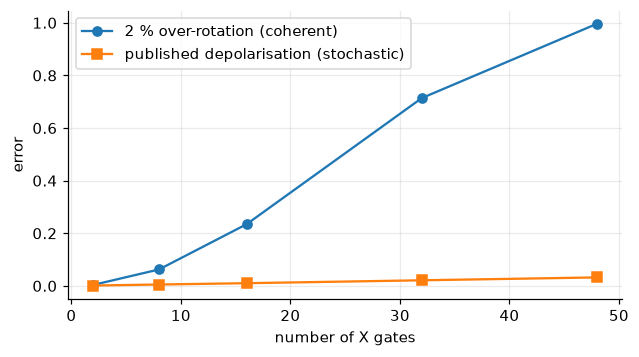

In [3]:
ns = [2, 8, 16, 32, 48]
coh = [1 - success(run("iqm_emerald", repeated("x q[0]", n), shots=50000,
                        noise={**COHERENT_ONLY, "overrotation": 0.02}), ["0"]) for n in ns]
dep = [1 - success(run("iqm_emerald", repeated("x q[0]", n), shots=50000,
                        noise={"model": "device", "relaxation": False, "idle": False, "readout": False,
                               "coherent": False, "crosstalk": False}), ["0"]) for n in ns]
fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.plot(ns, coh, "o-", label="2 % over-rotation (coherent)")
ax.plot(ns, dep, "s-", label="published depolarisation (stochastic)")
ax.set_xlabel("number of X gates"); ax.set_ylabel("error"); ax.legend(); plt.show()

## 3. Echoes cancel coherent errors

Alternating X and -X (written as rx(π) and rx(-π)) cancels the over-rotation instead of accumulating it.

In [4]:
n = 32
same = repeated("rx(pi) q[0]", n)
echo = program(1, [line for _ in range(n // 2) for line in ("rx(pi) q[0]", "barrier q[0]", "rx(-pi) q[0]", "barrier q[0]")])
for name, prog in (("all rx(pi)", same), ("alternating rx(pi), rx(-pi)", echo)):
    err = 1 - success(run("iqm_emerald", prog, shots=50000, noise={**COHERENT_ONLY, "overrotation": 0.02}), ["0"])
    print(f"{name:30s} error after {n} gates: {err:.4f}")

all rx(pi)                     error after 32 gates: 0.7139
alternating rx(pi), rx(-pi)    error after 32 gates: 0.0000


## 4. ZZ crosstalk on a spectator

During a two-qubit gate, a neighbouring spectator picks up a phase from ZZ crosstalk. A spectator prepared in |+⟩ and measured in the X basis shows the phase as a loss of its |+⟩ probability.

In [5]:
def spectator_program(gates):
    body = [line for _ in range(gates) for line in ("cz q[0],q[1]", "barrier q[0],q[1],q[2]")]
    return program(3, ["h q[2]", *body, "h q[2]"], measure=False) + "measure q[2] -> c[2];\n"
rows = []
for zz in (0.0, 0.02, 0.05, 0.1):
    for gates in (4, 16):
        r = run("iqm_emerald", spectator_program(gates), shots=50000,
                noise={**COHERENT_ONLY, "coherent": False, "crosstalk": True, "crosstalk_zz_rad": zz})
        p_plus = sum(v for k, v in r["result"]["counts"].items() if k[0] == "0") / 50000
        rows.append({"ZZ rad per gate": zz, "CZ gates": gates, "P(spectator stays |+>)": round(p_plus, 4)})
pd.DataFrame(rows).pivot(index="ZZ rad per gate", columns="CZ gates", values="P(spectator stays |+>)")

CZ gates,4,16
ZZ rad per gate,,
0.00,1.0000,1.0000
0.02,0.9992,0.9782
0.05,0.9947,0.8635
0.10,0.9782,0.5334


Whether a spectator is affected depends on the device's coupling map; the twins apply crosstalk only to coupled neighbours of the gate's qubits.

## Takeaways

- Coherent errors grow quadratically and can be cancelled by echoes; stochastic errors cannot.
- Crosstalk acts on qubits that are not part of the gate at all.